<a href="https://colab.research.google.com/github/OJB-Quantum/Qiskit-Metal-to-Litho/blob/main/Python%20Code_Qiskit%20Metal_Designs/12_Flux_Tunable_Xmons_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

# 12-Qubit Flux-Tunable Processor

Quantum Metal builds two columns of six Xmon qubits on a 12 × 12 mm chip, in which a central coplanar waveguide (CPW) feedline addresses twelve readout resonators and side launchpads address twelve flux lines. Each native `RouteMeander` connects a qubit claw to a shorted `CoupledLineTee` secondary arm, then the combined trace length follows the specified quarter-wave model and supports frequency ordering.

## Layout parameters

| Parameter | Value or Quantum Metal option |
| --- | --- |
| Die | 12 × 12 mm |
| Qubit columns | $x=-2350$ µm and $x=2350$ µm |
| Qubit rows, top to bottom | $y=3150,1890,630,-630,-1890,-3150$ µm |
| Qubit names and frequency order | `Q01_L`, `Q01_R`, `Q02_L`, `Q02_R`, …, `Q06_L`, `Q06_R` |
| Readout targets | 6.050–6.820 GHz in 0.070 GHz steps |
| Xmon geometry | `cross_length=260um`, `cross_width=35um`, `cross_gap=20um` |
| Qubit orientations | Left: −90°; right: +90° |
| Readout claw | Length 190 µm, width 10 µm, gap 6 µm, ground spacing 5 µm |
| Josephson inductance | 15.903982052718824 nH, as component metadata |
| Feedline | Width 11.7 µm, gap 5.1 µm |
| Resonator | Width 10 µm, gap 6 µm, circular fillet radius 85 µm |
| Resonator leads | 250 µm at each route endpoint |
| Native meander spacing | 240 µm |
| Coupler | Length 260 µm, secondary exit length 250 µm, shorted termination |
| Feedline-to-resonator metal edge separation | 18 µm |
| `CoupledLineTee.coupling_space` | $18-5.1-6=6.9$ µm, measured between the two CPW gap boundaries |
| Flux local T | Top length 24 µm, width 5 µm, gap 3 µm, inductive ground spacing 4 µm |
| Flux fanout and taper | Width 6 µm, gap 3.5 µm, taper length 95 µm |
| Readout launchpads | Positions $y=\pm4700$ µm; width 260 µm, body length 320 µm, taper 260 µm, lead 45 µm, gap 58 µm |
| Flux launchpads | Positions $x=\pm4850$ µm, aligned to actual flux pins; width 260 µm, body length 170 µm, taper 240 µm, lead 45 µm, gap 58 µm |
| GDS layer 3 | Positive ground and readout metal, including clearances beneath flux routes |
| GDS layer 5 | Positive flux metal: local T, tapered fanout, and launchpad |
| GDS layer 9 | Twelve 35 × 20 µm lumped-junction markers |
| Ground-plane cheesing | Native layer-3 grid: 25 × 25 µm holes, 100 µm pitch |
| Cheese keep-out | Native 25 µm component buffer and 200 µm chip-edge margin |
| GDS precision | 1 nm |

The assumed phase velocity $v_p=1.20\times10^8$ m/s sets the total resonator length $\ell$ for each target frequency $f_r$, in the uniform transmission-line limit with an open qubit-facing end and a shorted coupler end.

$$
\ell=\frac{v_p}{4f_r}=\ell_{\mathrm{meander}}+\ell_{\mathrm{coupler}},\qquad f_r\propto\ell^{-1}.
$$

`RouteMeander.length` includes its circular bends, and the coupler contribution includes the same circular-bend correction; the displayed frequency column evaluates this length model, while an electromagnetic solve determines the loaded resonances. Layer 9 holds symbolic junction sheets.

## API documentation

[Quantum Metal installation](https://qiskit-community.github.io/qiskit-metal/installation.html) · [Quantum Metal repository and headless API](https://github.com/qiskit-community/qiskit-metal) · [Transmon cross geometry](https://qiskit-community.github.io/qiskit-metal/circuit-examples/A.Qubits/01-Transmon_cross.html) · [Built-in cheesing and keep-out options](https://qiskit-community.github.io/qiskit-metal/tut/3-Renderers/3.2-Export-your-design-to-GDS.html)


In [ ]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
!uv pip install -q quantum-metal

In [ ]:
"""This script builds a 12-qubit flux-tunable processor in Quantum Metal.
"""

# --- Control Knobs ---
CHIP_SIZE = "11mm"
METAL_LAYER = 3
FLUX_LAYER = 5
JUNCTION_MARKER_LAYER = 9
LEFT_X_UM, RIGHT_X_UM = -2350.0, 2350.0
ROW_Y_UM = (3150.0, 1890.0, 630.0, -630.0, -1890.0, -3150.0)
READOUT_FREQUENCIES_GHZ = (
    6.050, 6.120, 6.190, 6.260, 6.330, 6.400,
    6.470, 6.540, 6.610, 6.680, 6.750, 6.820,
)
PHASE_VELOCITY_M_S = 1.20e8
LENGTH_TOLERANCE_UM = 5.0
FEED_WIDTH_UM, FEED_GAP_UM = 11.7, 5.1
READOUT_WIDTH_UM, READOUT_GAP_UM = 10.0, 6.0
READOUT_FILLET_UM = 85.0
READOUT_LEAD_UM = 250.0
COUPLING_LENGTH_UM = 260.0
COUPLING_EDGE_GAP_UM = 18.0
MEANDER_SPACING_UM = 240.0
CROSS_LENGTH, CROSS_WIDTH, CROSS_GAP = "260um", "35um", "20um"
CLAW_LENGTH, CLAW_WIDTH, CLAW_GAP = "190um", "10um", "6um"
JOSEPHSON_INDUCTANCE_NH = 15.903982052718824
FLUX_WIDTH_UM, FLUX_GAP_UM = 6.0, 3.5
FLUX_LOCAL_WIDTH_UM, FLUX_LOCAL_GAP_UM = 5.0, 3.0
FLUX_TAPER_UM = 95.0
FLUX_PAD_X_UM = 4850.0
READOUT_PAD_Y_UM = 4700.0
OUTPUT_FILENAME = "12 Flux Tunable Qubits.gds"

# --- Imports and Design ---
import os
import logging
from importlib.metadata import version
from pathlib import Path

os.environ.setdefault("QISKIT_METAL_HEADLESS", "True")

import gdstk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import PolyCollection
import qiskit_metal as qm
from IPython.display import FileLink, display
from qiskit_metal import Dict, designs
from qiskit_metal.qlibrary.core import QComponent
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.qubits.transmon_cross_fl import TransmonCrossFL
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.renderers.renderer_gds.gds_renderer import QGDSRenderer
from shapely.geometry import Polygon

plt.rcParams['figure.dpi'] = 200

assert len(READOUT_FREQUENCIES_GHZ) == 2 * len(ROW_Y_UM)
assert len({METAL_LAYER, FLUX_LAYER, JUNCTION_MARKER_LAYER}) == 3
assert COUPLING_EDGE_GAP_UM > FEED_GAP_UM + READOUT_GAP_UM
design = designs.DesignPlanar(overwrite_enabled=True, enable_renderers=False)
design.chips.main.size.size_x = CHIP_SIZE
design.chips.main.size.size_y = CHIP_SIZE
design.variables.cpw_width = f"{READOUT_WIDTH_UM}um"
design.variables.cpw_gap = f"{READOUT_GAP_UM}um"
gds_renderer = QGDSRenderer(design)
design.renderers.gds = gds_renderer
qubits, couplers, flux_pads, flux_routes, resonators = [], [], [], [], []
sites, length_records = [], []
print(f"Quantum Metal {version('quantum-metal')}")

Quantum Metal 0.9.0


In [ ]:
# --- Qubits and Readout Couplers ---
for row, y_um in enumerate(ROW_Y_UM):
    for side, x_um, angle in (
        ("L", LEFT_X_UM, -90), ("R", RIGHT_X_UM, 90)
    ):
        index = len(sites)
        name = f"Q{row + 1:02d}_{side}"
        qubit = TransmonCrossFL(
            design, name,
            options=Dict(
                pos_x=f"{x_um}um", pos_y=f"{y_um}um",
                orientation=str(angle), layer=str(METAL_LAYER),
                cross_length=CROSS_LENGTH, cross_width=CROSS_WIDTH,
                cross_gap=CROSS_GAP, make_fl=True,
                fl_options=Dict(
                    t_top="24um", t_offset="0um", t_inductive_gap="4um",
                    t_width=f"{FLUX_LOCAL_WIDTH_UM}um",
                    t_gap=f"{FLUX_LOCAL_GAP_UM}um",
                ),
                connection_pads=Dict(c=Dict(
                    connector_location="90", connector_type="0",
                    claw_length=CLAW_LENGTH, claw_width=CLAW_WIDTH,
                    claw_gap=CLAW_GAP, claw_cpw_length="0um",
                    claw_cpw_width=f"{READOUT_WIDTH_UM}um",
                    ground_spacing="5um",
                )),
                hfss_inductance=f"{JOSEPHSON_INDUCTANCE_NH}nH",
                aedt_hfss_inductance=f"{JOSEPHSON_INDUCTANCE_NH}nH",
            ),
        )
        # Paired couplers share their primary conductor on the central feedline.
        # Their secondary conductors face opposite qubit columns.
        coupler = CoupledLineTee(
            design, f"CLT_{name}",
            options=Dict(
                pos_x="0um", pos_y=f"{y_um}um",
                orientation="270" if side == "L" else "90",
                mirror=(side == "R") != bool(row % 2),
                layer=str(METAL_LAYER),
                prime_width=f"{FEED_WIDTH_UM}um",
                prime_gap=f"{FEED_GAP_UM}um",
                second_width=f"{READOUT_WIDTH_UM}um",
                second_gap=f"{READOUT_GAP_UM}um",
                coupling_length=f"{COUPLING_LENGTH_UM}um",
                coupling_space=(
                    f"{COUPLING_EDGE_GAP_UM - FEED_GAP_UM - READOUT_GAP_UM}um"
                ),
                down_length=f"{READOUT_LEAD_UM}um",
                fillet=f"{READOUT_FILLET_UM}um",
                open_termination=False,
            ),
        )
        qubits.append(qubit)
        couplers.append(coupler)
        sites.append(Dict(name=name, row=row, side=side, x_um=x_um, y_um=y_um))

# --- Feedline and Wirebond Launchpads ---
readout_pads = []
for suffix, y_um, angle in (
    ("top", READOUT_PAD_Y_UM, -90),
    ("bottom", -READOUT_PAD_Y_UM, 90),
):
    readout_pads.append(LaunchpadWirebond(
        design, f"wb_readout_{suffix}",
        options=Dict(
            pos_x="0um", pos_y=f"{y_um}um", orientation=str(angle),
            layer=str(METAL_LAYER), trace_width=f"{FEED_WIDTH_UM}um",
            trace_gap=f"{FEED_GAP_UM}um", lead_length="45um",
            pad_width="260um", pad_height="320um", pad_gap="58um",
            taper_height="260um",
        ),
    ))

feedline = RouteStraight(
    design, "readout_feedline",
    options=Dict(
        layer=str(METAL_LAYER), trace_width=f"{FEED_WIDTH_UM}um",
        trace_gap=f"{FEED_GAP_UM}um",
        pin_inputs=Dict(
            start_pin=Dict(component="wb_readout_bottom", pin="tie"),
            end_pin=Dict(component="wb_readout_top", pin="tie"),
        ),
    ),
)

for site, qubit in zip(sites, qubits):
    sign = -1 if site.side == "L" else 1
    tap = np.asarray(qubit.pins.flux_line.middle, dtype=float)
    assert sign * (tap[0] * 1000 - site.x_um) > 0
    flux_pads.append(LaunchpadWirebond(
        design, f"wb_flux_{site.name}",
        options=Dict(
            pos_x=f"{sign * FLUX_PAD_X_UM}um", pos_y=f"{tap[1]}mm",
            orientation="0" if sign < 0 else "180",
            layer=str(FLUX_LAYER), trace_width=f"{FLUX_WIDTH_UM}um",
            trace_gap=f"{FLUX_GAP_UM}um", lead_length="45um",
            pad_width="260um", pad_height="170um", pad_gap="58um",
            taper_height="240um",
        ),
    ))

# --- Frequency-Targeted Native Meanders ---
for site, qubit, coupler, frequency_ghz in zip(
    sites, qubits, couplers, READOUT_FREQUENCIES_GHZ
):
    target_mm = PHASE_VELOCITY_M_S / (4 * frequency_ghz * 1e9) * 1e3
    # Include the secondary coupler arm in the total quarter-wave length.
    secondary = coupler.qgeometry_table("path")
    secondary = secondary[secondary.name == "second_cpw"].iloc[0]
    secondary_mm = (
        secondary.geometry.length
        - (2 - np.pi / 2) * float(secondary.fillet)
    )
    route = RouteMeander(
        design, f"rr_{site.name}",
        options=Dict(
            layer=str(METAL_LAYER), trace_width=f"{READOUT_WIDTH_UM}um",
            trace_gap=f"{READOUT_GAP_UM}um",
            pin_inputs=Dict(
                start_pin=Dict(component=qubit.name, pin="c"),
                end_pin=Dict(component=coupler.name, pin="second_end"),
            ),
            total_length=f"{target_mm - secondary_mm:.12f}mm",
            fillet=f"{READOUT_FILLET_UM}um",
            lead=Dict(
                start_straight=f"{READOUT_LEAD_UM}um",
                end_straight=f"{READOUT_LEAD_UM}um",
            ),
            meander=Dict(spacing=f"{MEANDER_SPACING_UM}um", asymmetry="0um"),
        ),
    )
    resonators.append(route)
    actual_mm = route.length + secondary_mm
    length_records.append({
        "qubit": site.name, "target_GHz": frequency_ghz,
        "target_um": target_mm * 1000,
        "meander_um": route.length * 1000,
        "coupler_um": secondary_mm * 1000,
        "total_um": actual_mm * 1000,
        "error_um": (actual_mm - target_mm) * 1000,
        "length_model_GHz": PHASE_VELOCITY_M_S / (4 * actual_mm * 1e6),
    })

# --- Flux Tapers and Layer Assembly ---
# The complete build cell assembles native components before adding the
# explicit tapers and assigning the local flux features to the flux mask.
for site, qubit, pad in zip(sites, qubits, flux_pads):
    sign = -1 if site.side == "L" else 1
    start = np.asarray(qubit.pins.flux_line.middle, dtype=float)
    end = np.asarray(pad.pins.tie.middle, dtype=float)
    taper_end = start + np.array([sign * FLUX_TAPER_UM / 1000, 0.0])
    half_local = FLUX_LOCAL_WIDTH_UM / 2000
    half_main = FLUX_WIDTH_UM / 2000
    outer_local = half_local + FLUX_LOCAL_GAP_UM / 1000
    outer_main = half_main + FLUX_GAP_UM / 1000
    assert np.isclose(start[1], end[1])

    flux = QComponent(design, f"flux_{site.name}", make=False,
                      options=Dict(layer=str(FLUX_LAYER)))
    for label, a, b, width, gap in (
        ("start", taper_end, start, half_local * 2, FLUX_LOCAL_GAP_UM / 1000),
        ("end", taper_end, end, half_main * 2, FLUX_GAP_UM / 1000),
    ):
        flux.add_pin(label, np.array([a, b]), width=width, gap=gap,
                     input_as_norm=True)
    flux.add_qgeometry("poly", {"taper": Polygon([
        (start[0], start[1] - half_local),
        (taper_end[0], start[1] - half_main),
        (end[0], end[1] - half_main), (end[0], end[1] + half_main),
        (taper_end[0], start[1] + half_main),
        (start[0], start[1] + half_local),
    ])}, layer=FLUX_LAYER)
    flux.add_qgeometry("poly", {"taper_cut": Polygon([
        (start[0], start[1] - outer_local),
        (taper_end[0], start[1] - outer_main),
        (end[0], end[1] - outer_main), (end[0], end[1] + outer_main),
        (taper_end[0], start[1] + outer_main),
        (start[0], start[1] + outer_local),
    ])}, subtract=True, layer=FLUX_LAYER)
    flux.status = "good"
    design.connect_pins(qubit.id, "flux_line", flux.id, "start")
    design.connect_pins(flux.id, "end", pad.id, "tie")
    flux_routes.append(flux)

    # Place the complete local T on the same mask as its flux line.
    paths = design.qgeometry.tables["path"]
    local_flux = ((paths.component == qubit.id)
                  & paths.name.isin(["h_line", "v_line", "h_line_sub", "v_line_sub"]))
    paths.loc[local_flux, "layer"] = FLUX_LAYER

# Clear the lower ground beneath the upper-layer flux metal and its CPW gaps.
# Local T, taper, route, and launchpad therefore share a continuous layer-5 net.
for table_name in ("poly", "path"):
    table = design.qgeometry.tables[table_name]
    flux_cuts = table[(table.layer == FLUX_LAYER) & table["subtract"]].copy()
    for _, cut in flux_cuts.iterrows():
        owner = design._components[int(cut.component)]
        if table_name == "path":
            owner.add_qgeometry(
                "path", {f"ground_{cut['name']}": cut.geometry},
                width=float(cut.width), fillet=float(cut.fillet),
                subtract=True, layer=METAL_LAYER,
            )
        else:
            owner.add_qgeometry(
                "poly", {f"ground_{cut['name']}": cut.geometry},
                subtract=True, layer=METAL_LAYER,
            )

# Lumped-junction geometry forms layer-9 markers.
junction_table = design.qgeometry.tables["junction"].copy(deep=True)
for _, junction in junction_table.iterrows():
    owner = design._components[int(junction.component)]
    owner.add_qgeometry(
        "poly", {"junction_marker": junction.geometry.buffer(
            float(junction.width) / 2, cap_style=2,
        )}, layer=JUNCTION_MARKER_LAYER,
    )

# --- Geometry and Length Checks ---
length_table = pd.DataFrame(length_records)
assert length_table.error_um.abs().max() <= LENGTH_TOLERANCE_UM
assert len(qubits) == len(resonators) == len(flux_routes) == len(sites)
for component in design.components.values():
    assert component.status == "good", component.name
for table_name in ("poly", "path"):
    table = design.qgeometry.tables[table_name]
    assert table.geometry.is_valid.all(), table_name
    assert not table.geometry.is_empty.any(), table_name
    assert np.isfinite(table.total_bounds).all(), table_name
display(length_table.round(4))
print(f"{len(qubits)} qubits; {len(resonators)} resonators; "
      f"{len(flux_routes)} flux lines; {len(readout_pads) + len(flux_pads)} launchpads")

  self.tables[kind] = pd.concat(



,qubit,target_GHz,target_um,meander_um,coupler_um,total_um,error_um,length_model_GHz
0,Q01_L,6.05,4958.6777,4485.1600,473.5177,4958.6777,0.0,6.05
1,Q01_R,6.12,4901.9608,4428.4431,473.5177,4901.9608,-0.0,6.12
2,Q02_L,6.19,4846.5267,4373.0090,473.5177,4846.5267,-0.0,6.19
3,Q02_R,6.26,4792.3323,4318.8146,473.5177,4792.3323,-0.0,6.26
4,Q03_L,6.33,4739.3365,4265.8188,473.5177,4739.3365,-0.0,6.33
5,Q03_R,6.40,4687.5000,4213.9823,473.5177,4687.5000,-0.0,6.40
6,Q04_L,6.47,4636.7852,4163.2675,473.5177,4636.7852,0.0,6.47
7,Q04_R,6.54,4587.1560,4113.6383,473.5177,4587.1560,-0.0,6.54
8,Q05_L,6.61,4538.5779,4065.0602,473.5177,4538.5779,0.0,6.61
9,Q05_R,6.68,4491.0180,4017.5003,473.5177,4491.0180,-0.0,6.68


12 qubits; 12 resonators; 12 flux lines; 14 launchpads


  geopandas.GeoDataFrame(pd.concat(copy_subtract, ignore_index=False))

  geopandas.GeoDataFrame(pd.concat(copy_no_subtract, ignore_index=False))



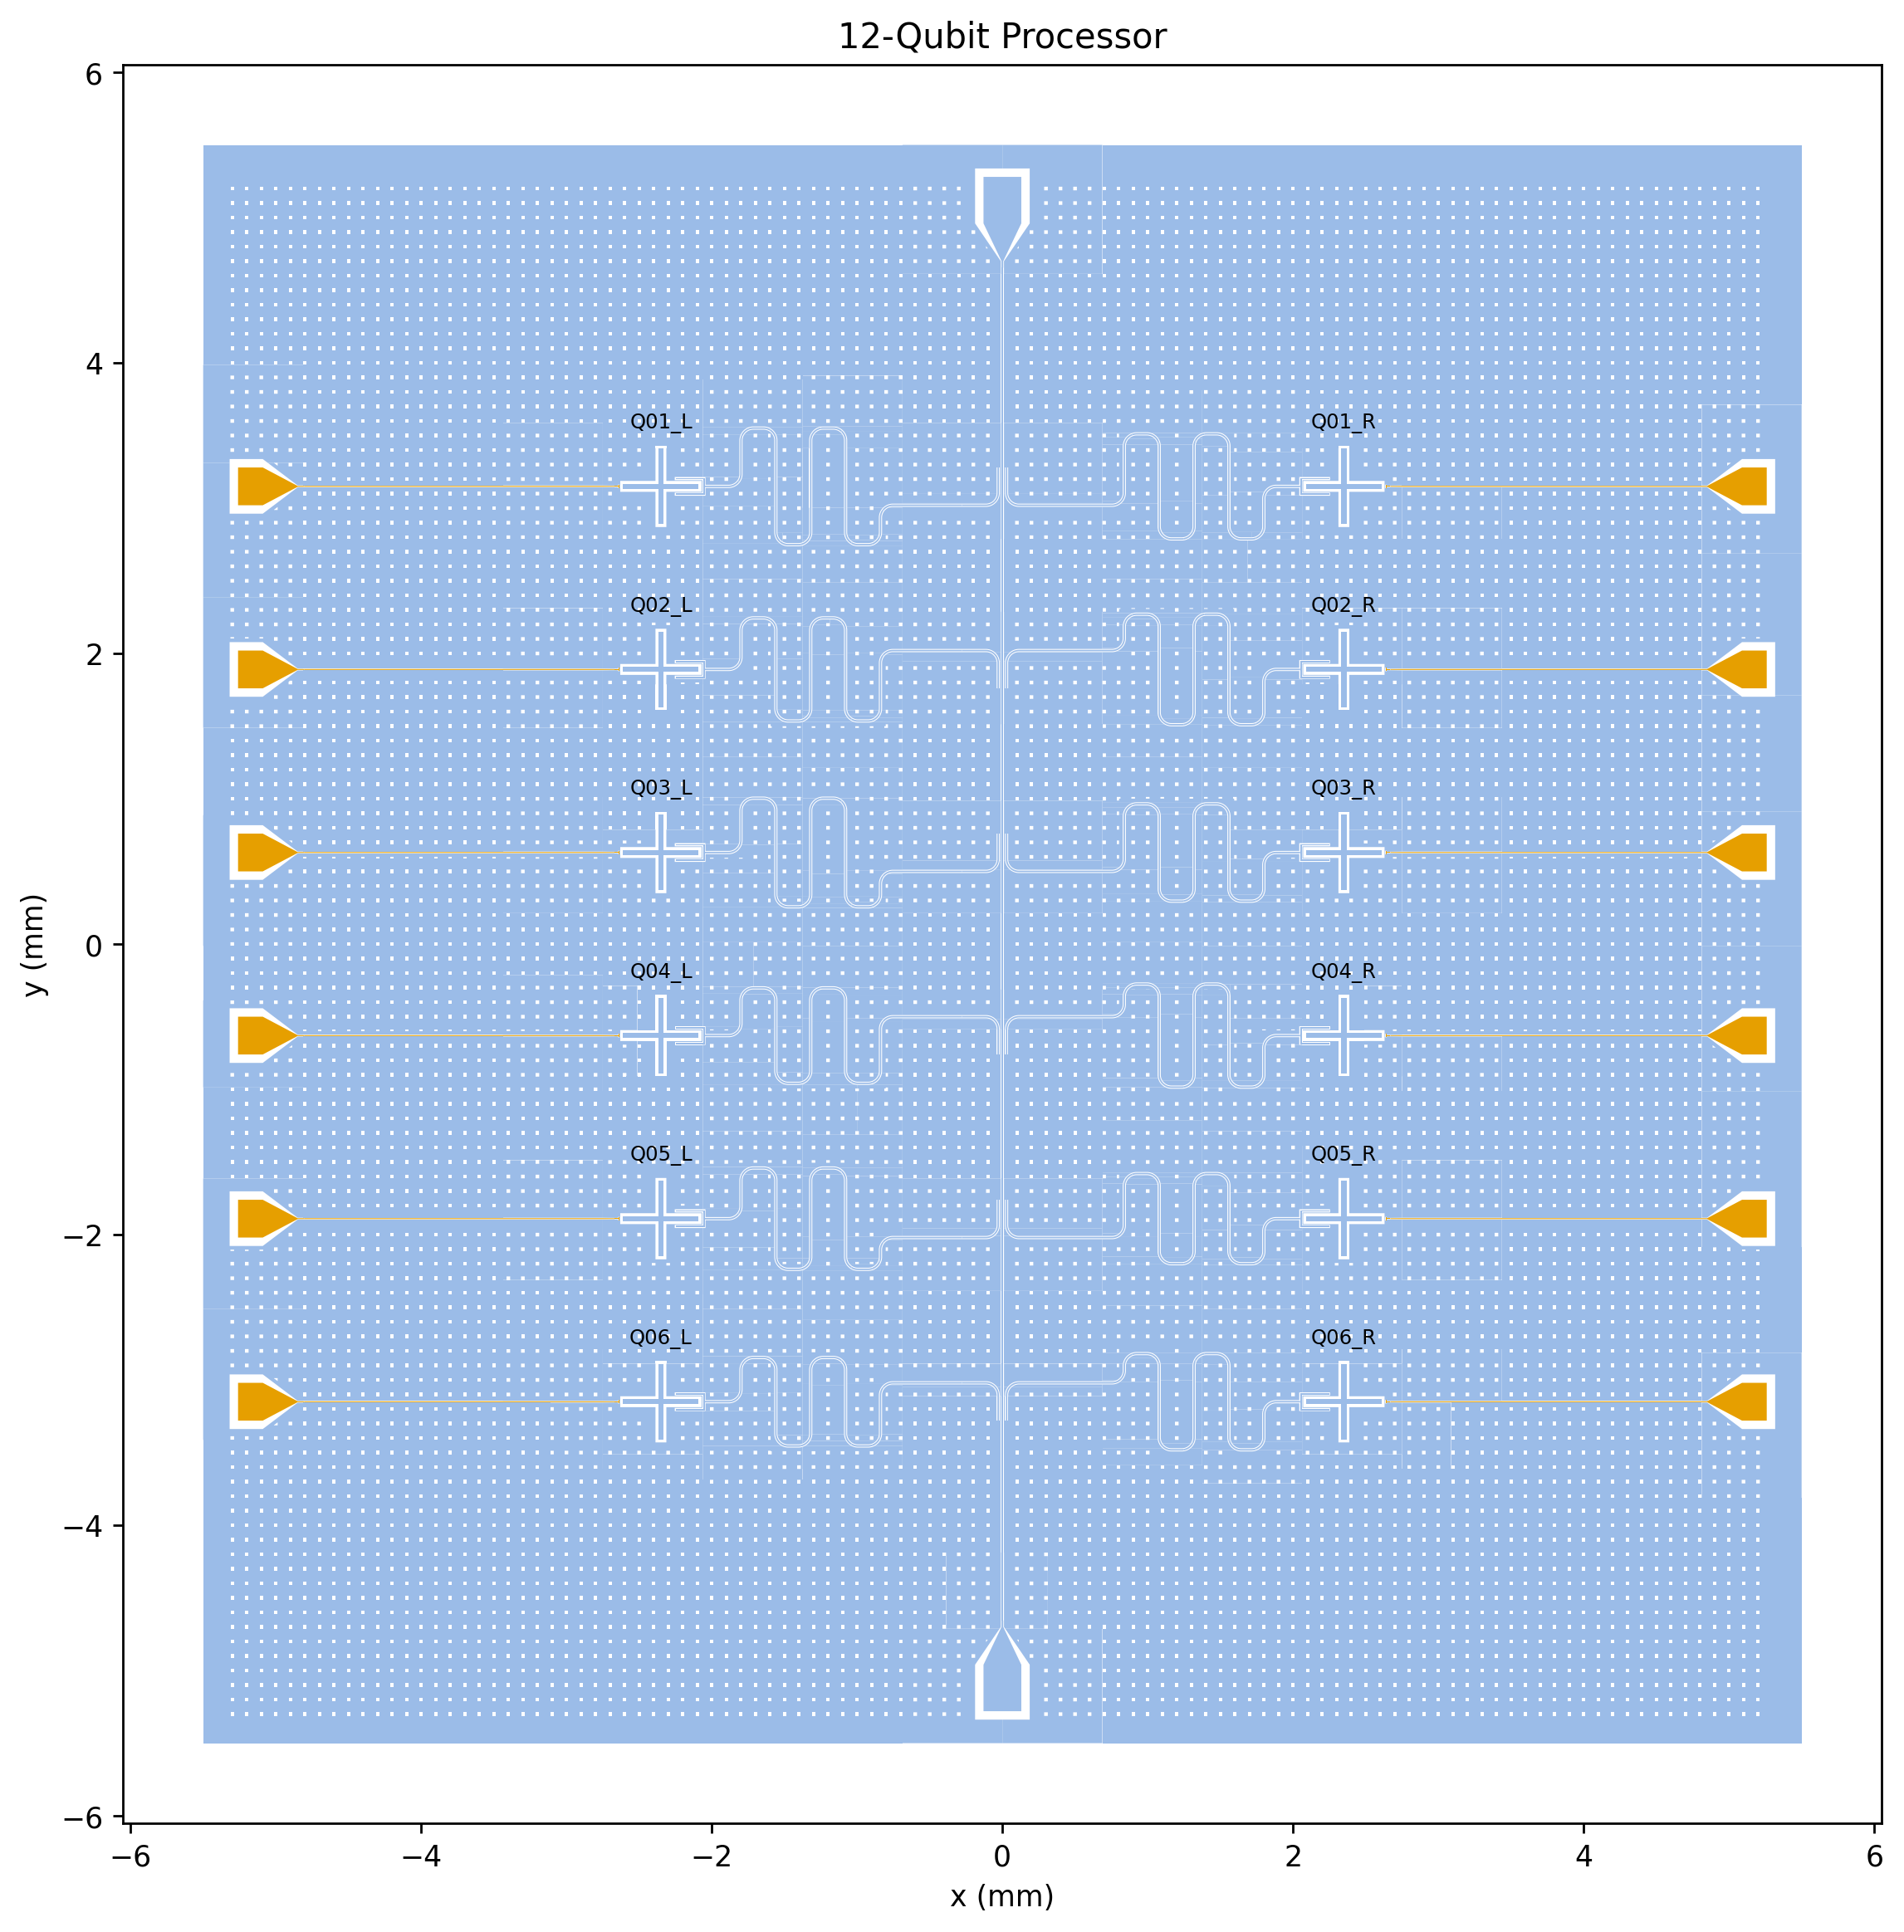

GDSII: 12 Flux Tunable Qubits.gds (1,231,354 bytes)
Layers: 3 = ground/readout; 5 = flux conductors; 9 = junction markers


/content/12 Flux Tunable Qubits.gds

In [ ]:
# --- Native Cheesing and GDS Export ---
out = Path.cwd() / OUTPUT_FILENAME
gds_renderer.options.precision = "1e-9"
gds_renderer.options.tolerance = "1e-6"
gds_renderer.options.fabricate = "True"
gds_renderer.options.short_segments_to_not_fillet = "False"
# Native hole size, pitch, component buffer, and chip-edge margin apply.
gds_renderer.options.cheese.view_in_file = Dict(main={
    METAL_LAYER: True, FLUX_LAYER: False, JUNCTION_MARKER_LAYER: False,
})
gds_renderer.options.no_cheese.view_in_file = Dict(main={
    METAL_LAYER: False, FLUX_LAYER: False, JUNCTION_MARKER_LAYER: False,
})
gds_renderer.options.path_filename = ""

# Markers already exist as polygons; do not substitute bundled fake junctions.
design.qgeometry.tables["junction"] = junction_table.iloc[:0].copy()
previous_log_level = qm.logger.level
qm.logger.setLevel(logging.ERROR)
try:
    export_status = gds_renderer.export_to_gds(str(out))
finally:
    qm.logger.setLevel(previous_log_level)
    design.qgeometry.tables["junction"] = junction_table
assert export_status and out.is_file() and out.stat().st_size > 0

# The upper flux layer contains patterned conductors, not another full plane.
gds_library = gds_renderer.lib
cell_names = {cell.name for cell in gds_library.cells}
for cell in gds_library.cells:
    for reference in list(cell.references):
        if (reference.cell_name == f"ground_main_{FLUX_LAYER}"
                or reference.cell_name not in cell_names):
            cell.remove(reference)
unused_flux_planes = [cell for cell in gds_library.cells
                      if cell.name == f"ground_main_{FLUX_LAYER}"]
if unused_flux_planes:
    gds_library.remove(*unused_flux_planes)
gds_library.write_gds(str(out))

# Reopen the written file and inspect every exported polygon.
verified_gds = gdstk.read_gds(str(out))
top_cells = verified_gds.top_level()
assert len(top_cells) == 1
exported_polygons = top_cells[0].get_polygons()
assert {p.layer for p in exported_polygons} == {
    METAL_LAYER, FLUX_LAYER, JUNCTION_MARKER_LAYER,
}
assert np.isclose(verified_gds.precision, 1e-9)
assert len([p for p in exported_polygons if p.layer == JUNCTION_MARKER_LAYER]) == 12

# --- In-Memory GDS Preview ---
fig, ax = plt.subplots(figsize=(11, 11), dpi=250)
for layer, color in ((METAL_LAYER, "#9bbce8"), (FLUX_LAYER, "#e69f00")):
    ax.add_collection(PolyCollection(
        [polygon.points for polygon in exported_polygons if polygon.layer == layer],
        facecolor=color, edgecolor="none", rasterized=True,
    ))
ax.autoscale_view()
ax.set_aspect("equal")
ax.set(xlabel="x (mm)", ylabel="y (mm)", title="12-Qubit Processor")
for site in sites:
    ax.text(site.x_um / 1000, site.y_um / 1000 + 0.4, site.name,
            ha="center", fontsize=7, fontfamily="DejaVu Sans", weight="normal")
plt.show()

print(f"GDSII: {out.name} ({out.stat().st_size:,} bytes)")
print("Layers: 3 = ground/readout; 5 = flux conductors; 9 = junction markers")
display(FileLink(str(out)))